# HW4 Part 2: Medical image transfer learning

**Model:** ImageNet-pretrained ResNet-18. **Dataset:** DermaMNIST (MedMNIST / HAM10000), 7 classes.

This notebook includes all training code and saves predictions, checkpoint, learning curves, ROC curves, confusion matrices, t-SNE and a machine-readable result file. Saved outputs were produced on a **local NVIDIA RTX 4070**, not in Google Colab. To rerun in Colab, choose **Runtime > Change runtime type > GPU** and run all cells. GPU/CPU and package differences can change results.

We retain the official 7,007 / 1,003 / 2,005 train / validation / test split. Only training images are augmented. Train-only class weights handle imbalance. Epoch 1 trains the new head; epochs 2-6 fine-tune layer4 and the head with frozen BatchNorm statistics. The best validation-accuracy checkpoint is selected before the test set is evaluated.

Sources: [MedMNIST](https://medmnist.com/) · [official code](https://github.com/MedMNIST/MedMNIST) · [torchvision ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)


In [1]:
import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'numpy==2.2.6', 'scipy', 'matplotlib', 'scikit-learn', 'medmnist==3.0.2'])
print('Python:', sys.version)


Python: 3.11.13 | packaged by Anaconda, Inc. | (main, Jun  5 2025, 13:03:15) [MSC v.1929 64 bit (AMD64)]


In [2]:
from pathlib import Path
__file__ = str(Path.cwd() / 'finetune.py')
"""ImageNet ResNet-18 transfer learning on the official DermaMNIST split."""
import argparse
import copy
import hashlib
import json
import os
from pathlib import Path
import random
import time

os.environ.setdefault('TORCH_HOME', str(Path(__file__).resolve().parent/'.cache/torch'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(__file__).resolve().parent/'.cache/matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import medmnist
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.manifold import TSNE
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import models, transforms


def evaluate(model, loader, device):
    model.eval()
    labels, probabilities, features = [], [], []
    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device)
            f = model.avgpool(model.layer4(model.layer3(model.layer2(model.layer1(model.maxpool(model.relu(model.bn1(model.conv1(x))))))))).flatten(1)
            prob = model.fc(f).softmax(1)
            labels.append(y.numpy().reshape(-1)); probabilities.append(prob.cpu().numpy()); features.append(f.cpu().numpy())
    y, prob, feat = np.concatenate(labels), np.concatenate(probabilities), np.concatenate(features)
    return y, prob, feat


def metrics(y, prob):
    return {'accuracy':float(accuracy_score(y, prob.argmax(1))),
            'balanced_accuracy':float(balanced_accuracy_score(y, prob.argmax(1))),
            'macro_ovr_auc':float(roc_auc_score(y, prob, multi_class='ovr', average='macro'))}


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--data',type=Path,default=Path('data/dermamnist'))
    parser.add_argument('--out',type=Path,default=Path('results/finetune'))
    parser.add_argument('--epochs',type=int,default=6)
    parser.add_argument('--batch-size',type=int,default=64)
    parser.add_argument('--seed',type=int,default=42)
    args = parser.parse_args()
    if args.epochs < 2:
        parser.error('Use at least 2 epochs so backbone fine-tuning actually occurs.')
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)
    torch.set_num_threads(4)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(args.seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    args.data.mkdir(parents=True,exist_ok=True); args.out.mkdir(parents=True,exist_ok=True)
    info=medmnist.INFO['dermamnist']; names=list(info['label'].values())
    weights=models.ResNet18_Weights.IMAGENET1K_V1
    normalize=transforms.Normalize([.485,.456,.406],[.229,.224,.225])
    train_tf=transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(),transforms.RandomVerticalFlip(),transforms.ToTensor(),normalize])
    eval_tf=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),normalize])
    sets={s:medmnist.DermaMNIST(split=s,root=str(args.data),download=True,transform=train_tf if s=='train' else eval_tf) for s in ['train','val','test']}
    # Keep official splits intact. No augmented copies enter validation or test.
    loaders={s:DataLoader(d,batch_size=args.batch_size,shuffle=s=='train',num_workers=0) for s,d in sets.items()}
    model=models.resnet18(weights=weights)
    for par in model.parameters(): par.requires_grad=False
    model.fc=nn.Linear(model.fc.in_features,len(names)); model.to(device)
    counts=np.bincount(sets['train'].labels.reshape(-1),minlength=len(names))
    class_weights=counts.sum()/(len(names)*counts)
    criterion=nn.CrossEntropyLoss(weight=torch.tensor(class_weights,dtype=torch.float32,device=device))
    optimizer=torch.optim.AdamW(model.fc.parameters(),lr=1e-3,weight_decay=1e-4)
    best_score=-1.; best_state=None; history=[]; start=time.time()
    print(json.dumps({'device':str(device),'counts':{s:len(d) for s,d in sets.items()},'class_counts':counts.tolist()}),flush=True)
    for epoch in range(args.epochs):
        if epoch==1:
            for par in model.layer4.parameters(): par.requires_grad=True
            optimizer=torch.optim.AdamW([{'params':model.layer4.parameters(),'lr':1e-4},{'params':model.fc.parameters(),'lr':3e-4}],weight_decay=1e-4)
        # Frozen BatchNorm statistics stay at the pretrained values.
        model.train()
        for mod in model.modules():
            if isinstance(mod,nn.BatchNorm2d): mod.eval()
        total_loss=0.; num=0; weighted_denominator=0.
        for x,y in loaders['train']:
            x=x.to(device); y=y.reshape(-1).long().to(device)
            optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(x),y); loss.backward(); optimizer.step()
            denominator=float(criterion.weight[y].sum())
            total_loss+=float(loss.detach())*denominator; weighted_denominator+=denominator; num+=len(x)
        y,prob,_=evaluate(model,loaders['val'],device)
        row={'epoch':epoch+1,'stage':'head' if epoch==0 else 'layer4_and_head','train_loss':total_loss/weighted_denominator,**{'val_'+k:v for k,v in metrics(y,prob).items()}}
        history.append(row); print(json.dumps(row),flush=True)
        if row['val_accuracy']>best_score:
            best_score=row['val_accuracy']; best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        (args.out/'history.json').write_text(json.dumps(history,indent=2))
    model.load_state_dict(best_state)
    torch.save({'model_state_dict':best_state,'classes':names,'best_epoch':best_epoch,'args':{k:str(v) if isinstance(v,Path) else v for k,v in vars(args).items()}},args.out/'best_model.pt')
    outputs={}
    for split in ['val','test']:
        y,prob,feat=evaluate(model,loaders[split],device); outputs[split]=metrics(y,prob)
        np.savez_compressed(args.out/f'{split}_predictions.npz',labels=y,probabilities=prob,features=feat)
        (args.out/f'{split}_classification_report.json').write_text(json.dumps(classification_report(y,prob.argmax(1),labels=list(range(len(names))),target_names=names,output_dict=True,zero_division=0),indent=2))
        fig,ax=plt.subplots(figsize=(8,7)); ConfusionMatrixDisplay(confusion_matrix(y,prob.argmax(1),labels=range(len(names))),display_labels=names).plot(ax=ax,xticks_rotation=65,colorbar=False,values_format='d')
        ax.set_title(f'DermaMNIST {split}: ImageNet ResNet-18'); fig.tight_layout(); fig.savefig(args.out/f'{split}_confusion.png',dpi=170); plt.close(fig)
        fig,ax=plt.subplots(figsize=(7,5))
        for k,name in enumerate(names):
            fpr,tpr,_=roc_curve(y==k,prob[:,k]); auc=roc_auc_score(y==k,prob[:,k]); ax.plot(fpr,tpr,label=f'{name}: {auc:.3f}')
        ax.plot([0,1],[0,1],'k--',alpha=.4); ax.set(xlabel='1 - specificity',ylabel='Sensitivity',title=f'{split}: one-vs-rest ROC'); ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(args.out/f'{split}_roc.png',dpi=170); plt.close(fig)
        if split=='val':
            emb=TSNE(n_components=2,random_state=args.seed,perplexity=30,init='pca',learning_rate='auto').fit_transform(feat)
            fig,ax=plt.subplots(figsize=(7,5))
            for k,name in enumerate(names): ax.scatter(*emb[y==k].T,s=9,alpha=.65,label=name)
            ax.set(title='Validation: t-SNE of 512-dimensional penultimate features',xlabel='t-SNE 1',ylabel='t-SNE 2'); ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(args.out/'val_tsne.png',dpi=170); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(10,3.5)); epochs=[r['epoch'] for r in history]
    axes[0].plot(epochs,[r['train_loss'] for r in history],'o-'); axes[0].set(xlabel='Epoch',ylabel='Weighted training loss')
    axes[1].plot(epochs,[r['val_accuracy'] for r in history],'o-',label='Accuracy'); axes[1].plot(epochs,[r['val_balanced_accuracy'] for r in history],'o-',label='Balanced accuracy'); axes[1].set(xlabel='Epoch',ylabel='Validation metric',ylim=(0,1)); axes[1].legend()
    fig.tight_layout(); fig.savefig(args.out/'learning_curves.png',dpi=170); plt.close(fig)
    dataset_file=args.data/'dermamnist.npz'
    result={'status':'completed_real_training','dataset':'DermaMNIST (MedMNIST), native 28x28 RGB resized to 224x224',
            'dataset_info':info,'dataset_sha256':hashlib.sha256(dataset_file.read_bytes()).hexdigest(),
            'model':'ResNet-18','pretrained_weights':'IMAGENET1K_V1','split_sizes':{s:len(d) for s,d in sets.items()},
            'seed':args.seed,'epochs':args.epochs,'best_epoch':best_epoch,'selection':'highest official validation accuracy; test evaluated only after checkpoint selection',
            'train_class_counts':counts.tolist(),'class_weights':class_weights.tolist(),'validation':outputs['val'],'test':outputs['test'],
            'elapsed_seconds':time.time()-start,'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
            'versions':{'torch':torch.__version__,'medmnist':medmnist.__version__,'numpy':np.__version__},
            'limitations':['Native 28x28 images lose clinical detail; resizing cannot restore it.','One fixed seed and one dataset; no clinical deployment or robustness claim.','Official split retained; patient grouping was not independently audited from raw source IDs.','t-SNE is descriptive and is not an accuracy measure.']}
    (args.out/'result.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
    print(json.dumps(result,indent=2),flush=True)


import sys
sys.argv = ['finetune.py', '--epochs', '6']
main()


{"device": "cuda", "counts": {"train": 7007, "val": 1003, "test": 2005}, "class_counts": [228, 359, 769, 80, 779, 4693, 99]}


{"epoch": 1, "stage": "head", "train_loss": 1.6693293381659857, "val_accuracy": 0.3898305084745763, "val_balanced_accuracy": 0.4611098819529733, "val_macro_ovr_auc": 0.829741992704894}


{"epoch": 2, "stage": "layer4_and_head", "train_loss": 1.4160971087122876, "val_accuracy": 0.44167497507477566, "val_balanced_accuracy": 0.4914647993102326, "val_macro_ovr_auc": 0.8463636532932447}


{"epoch": 3, "stage": "layer4_and_head", "train_loss": 1.1749626804673805, "val_accuracy": 0.609172482552343, "val_balanced_accuracy": 0.5439798044013501, "val_macro_ovr_auc": 0.9057480395381656}


{"epoch": 4, "stage": "layer4_and_head", "train_loss": 1.0808980060398874, "val_accuracy": 0.5463609172482552, "val_balanced_accuracy": 0.5163669484512576, "val_macro_ovr_auc": 0.885273577936006}


{"epoch": 5, "stage": "layer4_and_head", "train_loss": 0.9625388274901628, "val_accuracy": 0.6470588235294118, "val_balanced_accuracy": 0.6092130605011167, "val_macro_ovr_auc": 0.90518888954967}


{"epoch": 6, "stage": "layer4_and_head", "train_loss": 0.9174207087190316, "val_accuracy": 0.6660019940179461, "val_balanced_accuracy": 0.5380539434403603, "val_macro_ovr_auc": 0.9127274630667583}


{
  "status": "completed_real_training",
  "dataset": "DermaMNIST (MedMNIST), native 28x28 RGB resized to 224x224",
  "dataset_info": {
    "python_class": "DermaMNIST",
    "description": "The DermaMNIST is based on the HAM10000, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. The dataset consists of 10,015 dermatoscopic images categorized as 7 different diseases, formulized as a multi-class classification task. We split the images into training, validation and test set with a ratio of 7:1:2. The source images of 3\u00d7600\u00d7450 are resized into 3\u00d728\u00d728.",
    "url": "https://zenodo.org/records/10519652/files/dermamnist.npz?download=1",
    "MD5": "0744692d530f8e62ec473284d019b0c7",
    "url_64": "https://zenodo.org/records/10519652/files/dermamnist_64.npz?download=1",
    "MD5_64": "b70a2f5635c6199aeaa28c31d7202e1f",
    "url_128": "https://zenodo.org/records/10519652/files/dermamnist_128.npz?download=1",
    "MD5_128": "2defd78

In [3]:
# Improve figure label readability from saved predictions; no retraining.
import sys
from pathlib import Path
__file__ = str(Path.cwd()/'refresh_plots.py')
"""Render compact, readable class labels from saved predictions; no retraining."""
import os
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR',str(Path(__file__).resolve().parent/'.cache/matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix,roc_curve,roc_auc_score
from sklearn.manifold import TSNE

out=Path('results/finetune');names=['AKIEC','BCC','BKL','DF','MEL','NV','VASC']
for split in ['val','test']:
    r=np.load(out/f'{split}_predictions.npz');y=r['labels'];prob=r['probabilities']
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(confusion_matrix(y,prob.argmax(1),labels=range(7)),display_labels=names).plot(ax=ax,xticks_rotation=0,colorbar=False,values_format='d')
    ax.set_title(f'DermaMNIST {split}: ImageNet ResNet-18');fig.tight_layout();fig.savefig(out/f'{split}_confusion.png',dpi=170);plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,5))
    for k,name in enumerate(names):
        fpr,tpr,_=roc_curve(y==k,prob[:,k]);auc=roc_auc_score(y==k,prob[:,k]);ax.plot(fpr,tpr,label=f'{name}: {auc:.3f}')
    ax.plot([0,1],[0,1],'k--',alpha=.4);ax.set(xlabel='1 - specificity',ylabel='Sensitivity',title=f'{split}: one-vs-rest ROC');ax.legend(fontsize=9);fig.tight_layout();fig.savefig(out/f'{split}_roc.png',dpi=170);plt.close(fig)
    if split=='val':
        emb=TSNE(n_components=2,random_state=42,perplexity=30,init='pca',learning_rate='auto').fit_transform(r['features'])
        fig,ax=plt.subplots(figsize=(7,5))
        for k,name in enumerate(names):ax.scatter(*emb[y==k].T,s=9,alpha=.65,label=name)
        ax.set(title='Validation: t-SNE of penultimate features',xlabel='t-SNE 1',ylabel='t-SNE 2');ax.legend(fontsize=9);fig.tight_layout();fig.savefig(out/'val_tsne.png',dpi=170);plt.close(fig)
print('Refreshed plots from saved predictions; model and metrics unchanged.')


Refreshed plots from saved predictions; model and metrics unchanged.


## Results and interpretation
- Best epoch: **6** (validation accuracy selection).
- Validation accuracy: **66.60%**; balanced accuracy: **53.81%**; macro one-vs-rest AUC: **0.913**.
- Held-out test accuracy: **67.73%**; balanced accuracy: **56.23%**; macro AUC: **0.914**.
- Always predicting the training-majority class achieves **66.90%** validation accuracy but **14.29%** balanced accuracy. The model's overall accuracy is close to that baseline; its higher balanced accuracy shows better minority-class coverage. Raw accuracy alone is insufficient.
- Native images are 28 x 28; resizing to 224 x 224 does not recover clinical detail. Official splits are retained, but raw patient identity leakage was not independently audited. One dataset and seed do not support a clinical claim. t-SNE is descriptive, not an accuracy score.


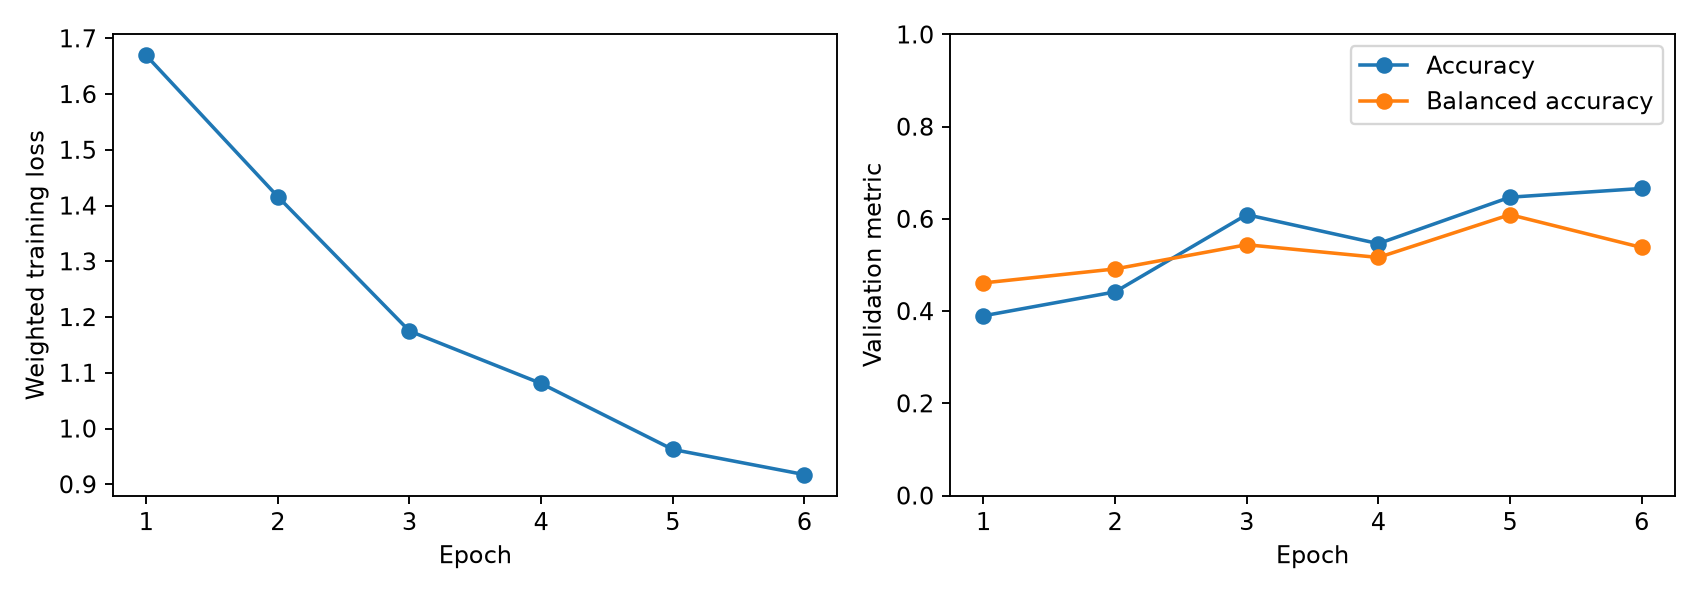

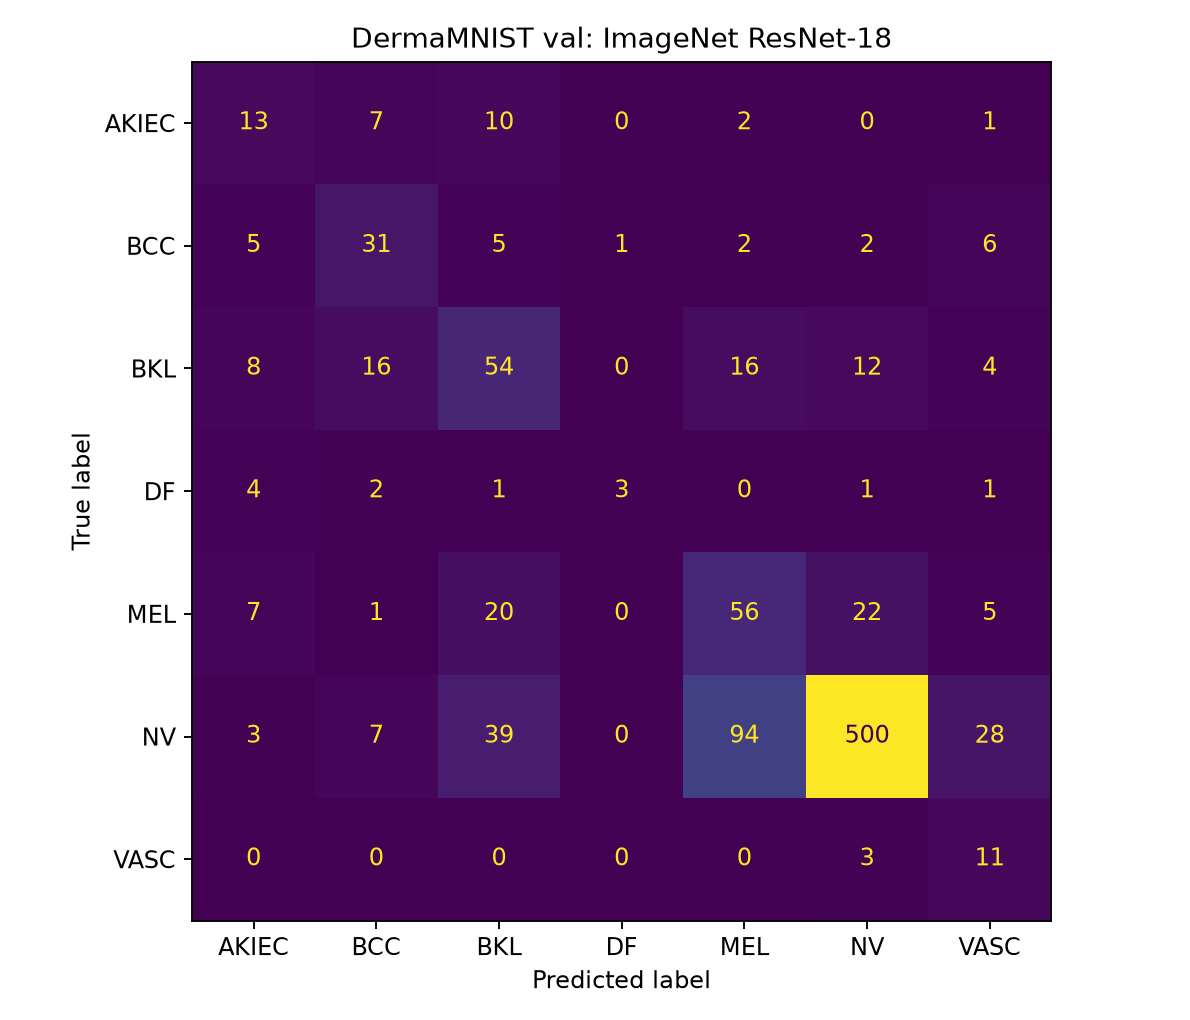

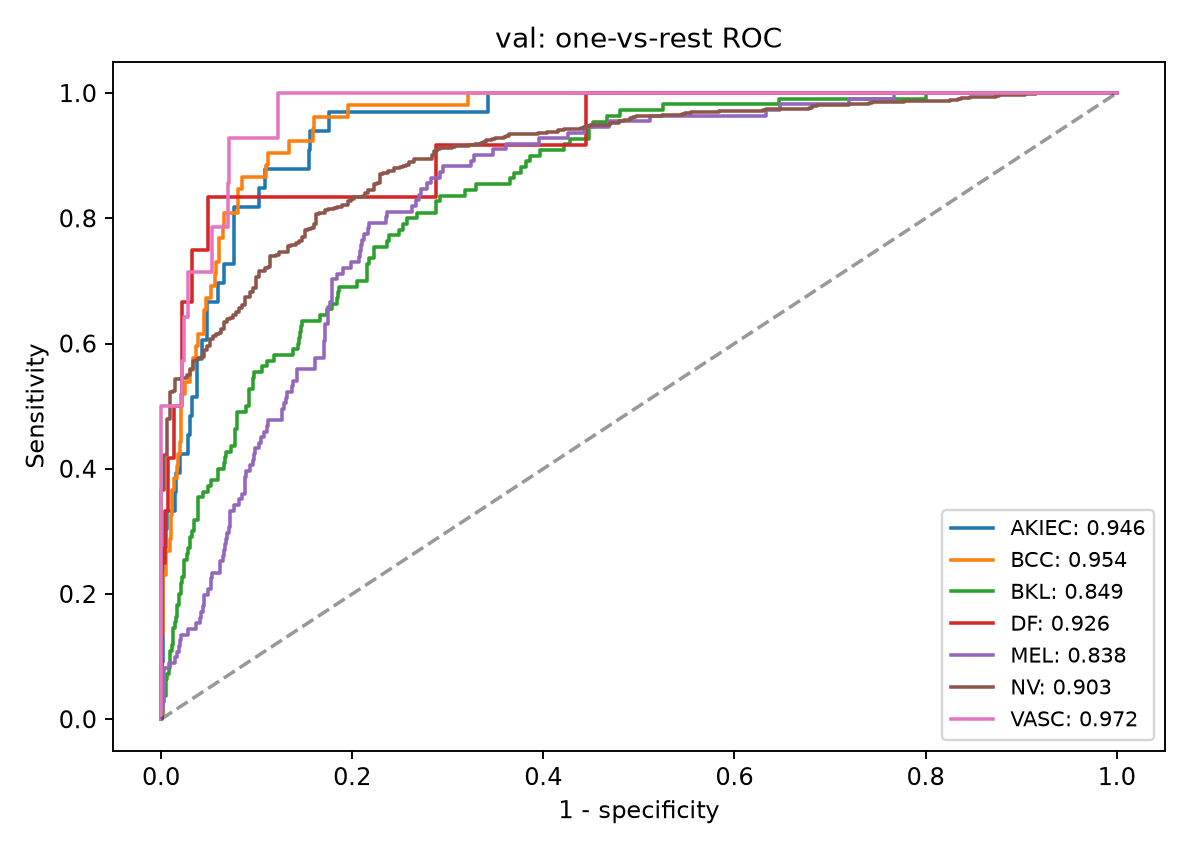

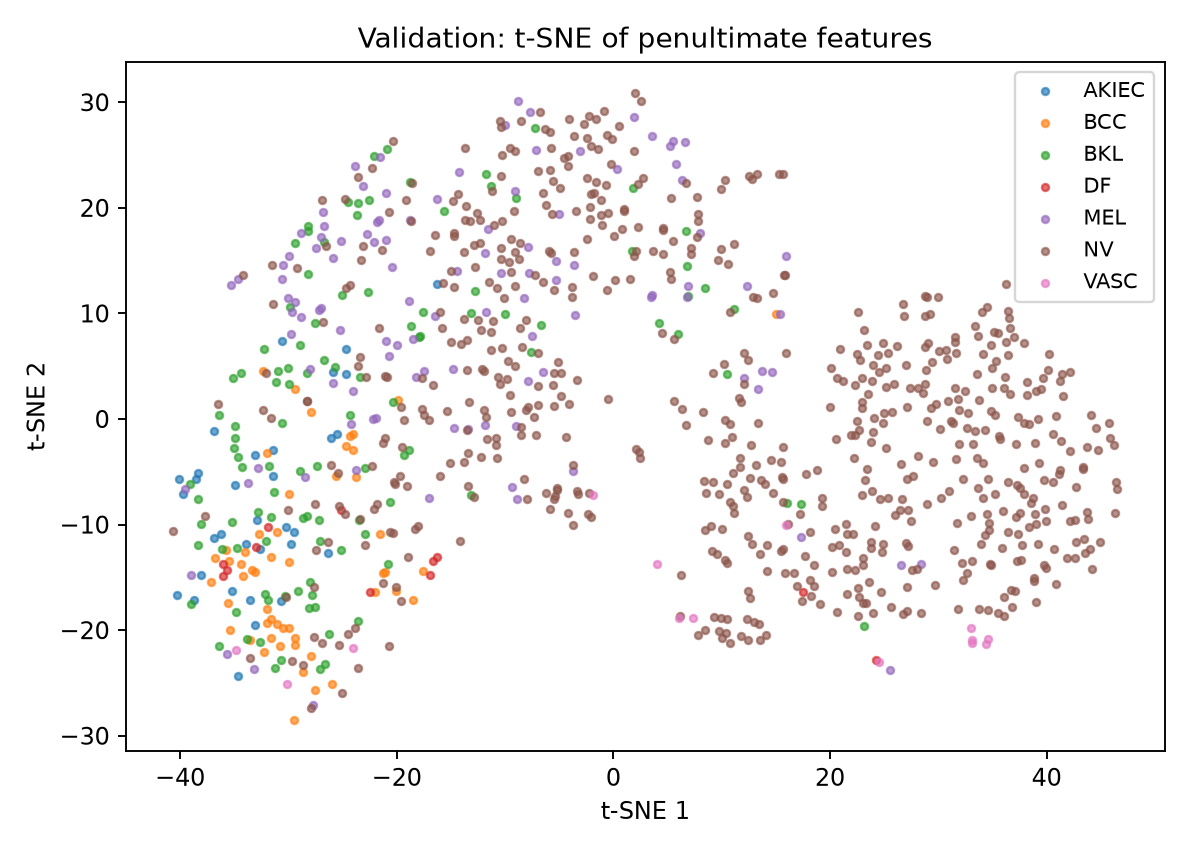

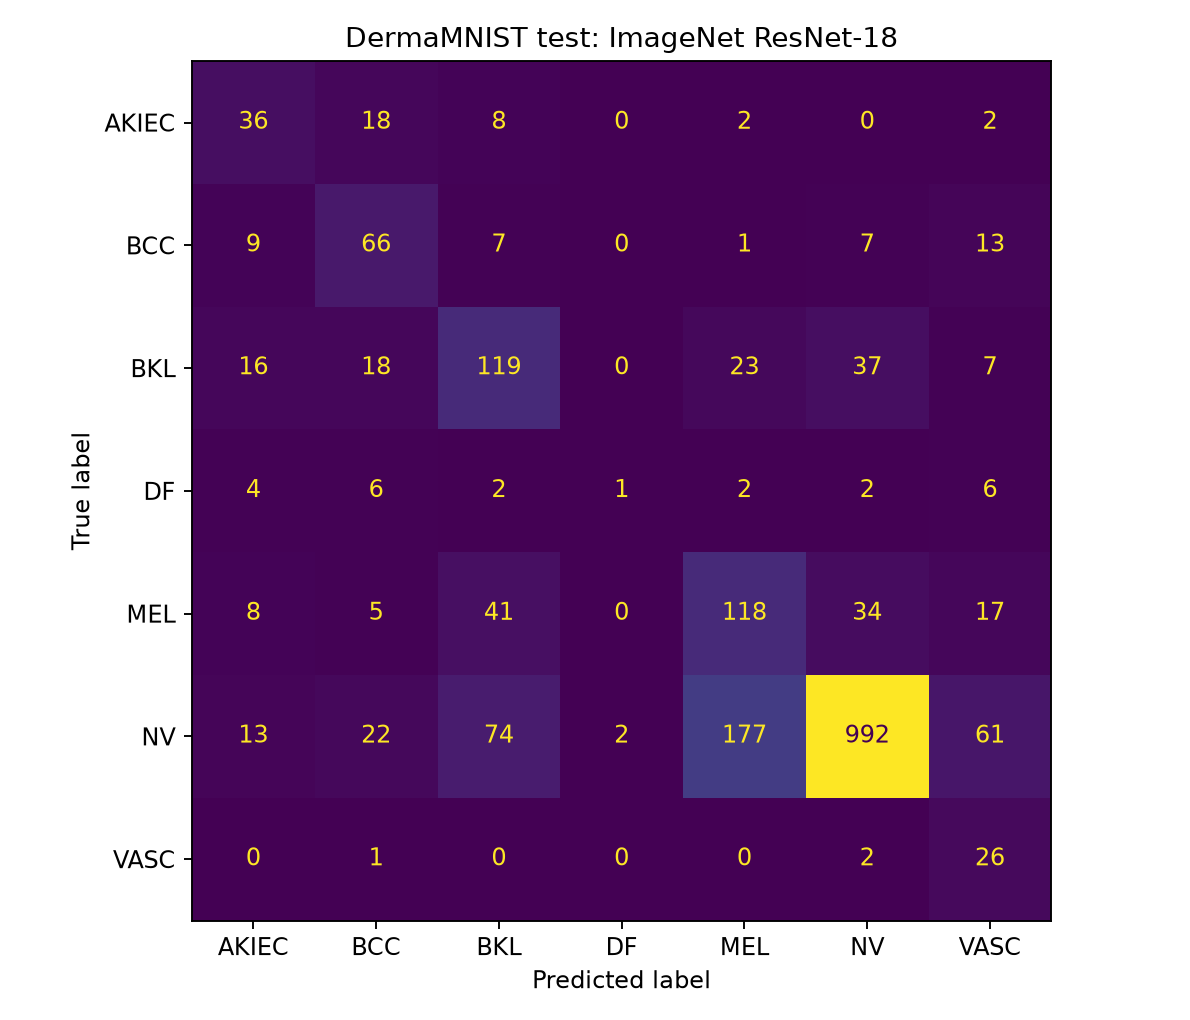

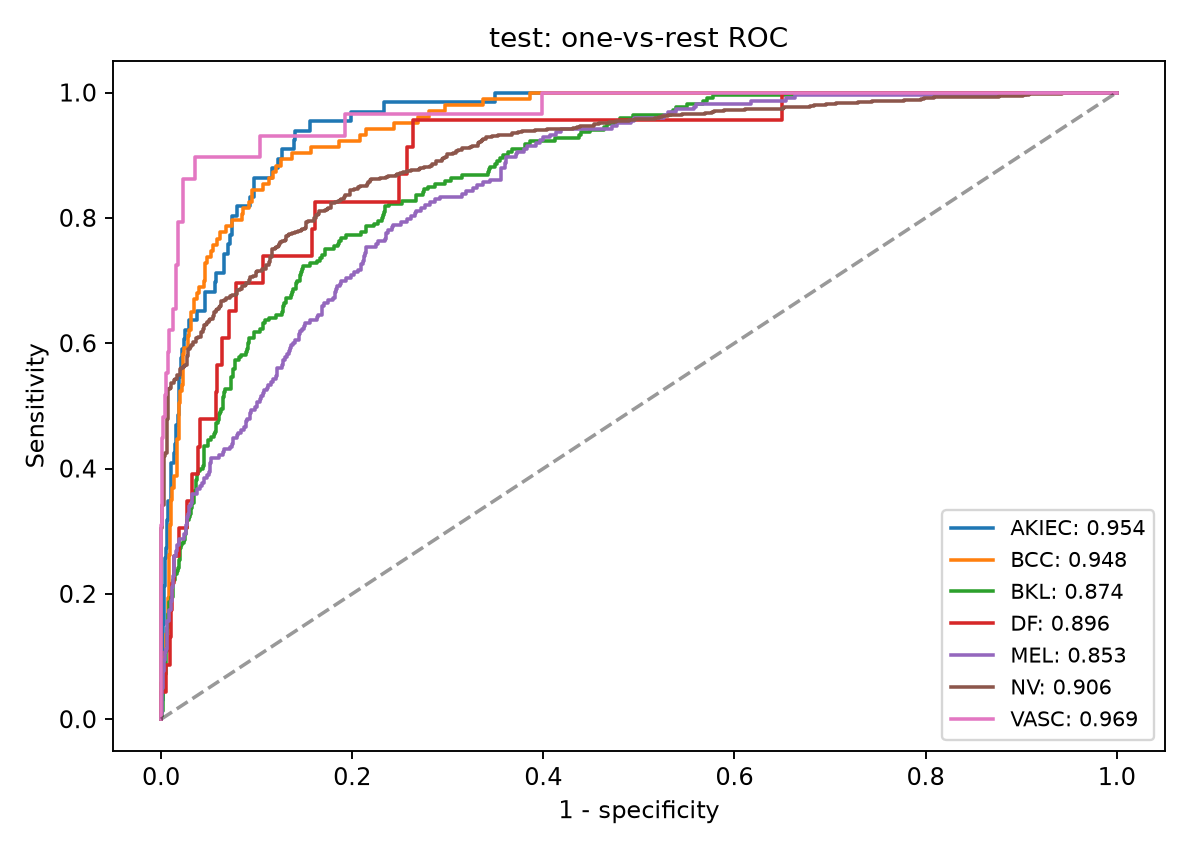

In [4]:
import json
from IPython.display import display, Image, Markdown
result = json.loads(Path('results/finetune/result.json').read_text())
val = result['validation']; test = result['test']
report = json.loads(Path('results/finetune/val_classification_report.json').read_text())
majority_name = list(result['dataset_info']['label'].values())[int(__import__('numpy').argmax(result['train_class_counts']))]
majority_val = report[majority_name]['support'] / result['split_sizes']['val']
display(Markdown(f"""## Results and interpretation
- Best epoch: **{result['best_epoch']}** (validation accuracy selection).
- Validation accuracy: **{val['accuracy']:.2%}**; balanced accuracy: **{val['balanced_accuracy']:.2%}**; macro one-vs-rest AUC: **{val['macro_ovr_auc']:.3f}**.
- Held-out test accuracy: **{test['accuracy']:.2%}**; balanced accuracy: **{test['balanced_accuracy']:.2%}**; macro AUC: **{test['macro_ovr_auc']:.3f}**.
- Always predicting the training-majority class achieves **{majority_val:.2%}** validation accuracy but **14.29%** balanced accuracy. The model's overall accuracy is close to that baseline; its higher balanced accuracy shows better minority-class coverage. Raw accuracy alone is insufficient.
- Native images are 28 x 28; resizing to 224 x 224 does not recover clinical detail. Official splits are retained, but raw patient identity leakage was not independently audited. One dataset and seed do not support a clinical claim. t-SNE is descriptive, not an accuracy score.
"""))
for name in ['learning_curves.png', 'val_confusion.png', 'val_roc.png', 'val_tsne.png', 'test_confusion.png', 'test_roc.png']:
    display(Image(filename='results/finetune/'+name))


In [5]:
# Colab: download the result files after running. Do not upload the dataset to GitHub.
import shutil
shutil.make_archive('HW4_Part2_results', 'zip', 'results/finetune')
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download('HW4_Part2_results.zip')
print('Saved HW4_Part2_results.zip')


Saved HW4_Part2_results.zip
